# **Laboratorio 2: Simulación e Inferencia — Airbnb Nueva York**  
INF280 Estadística Computacional, UTFSM — Grupo 25  
Integrantes: José Flores, Sebastian Alcaide, Pedro Ortiz y Miguel Primera

### Declaración de uso de herramientas de IA
Se utilizaron asistentes de IA como apoyo: ChatGPT/Codex para el análisis, el código y la actualización de los archivos, y Claude para la revisión. El grupo comprende cada línea de código y cada afirmación entregada y responde por el contenido.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Cada simulación crea de nuevo su generador: repetir su celda da el mismo
# resultado con los mismos datos, parámetros y versiones de los paquetes.
RANDOM_STATE = 2026
SEED_BOOTSTRAP = RANDOM_STATE
SEED_MC = RANDOM_STATE + 1

DECIMALES_ESTIMACION = 4
DECIMALES_COMPARACION = 5
DECIMALES_PORCENTAJE = 2

def numero(valor, decimales=DECIMALES_ESTIMACION):
    return f"{valor:.{decimales}f}".replace('.', ',')

def porcentaje(probabilidad):
    return numero(100 * probabilidad, DECIMALES_PORCENTAJE) + ' %'

def entero(valor):
    return f'{valor:,}'.replace(',', '.')

def mostrar_tabla(tabla, decimales=DECIMALES_ESTIMACION,
                  columnas_porcentaje=(), columnas_pp=()):
    # Solo cambia la presentación; los cálculos conservan todos los decimales.
    vista = tabla.copy()
    for columna in vista.columns:
        if columna in columnas_porcentaje:
            vista[columna] = tabla[columna].map(porcentaje)
        elif columna in columnas_pp:
            vista[columna] = tabla[columna].map(
                lambda x: '—' if pd.isna(x) else numero(x, DECIMALES_PORCENTAJE))
        elif pd.api.types.is_float_dtype(tabla[columna]):
            vista[columna] = tabla[columna].map(lambda x: numero(x, decimales))
    display(vista)

# Paquetes necesarios: numpy, pandas, matplotlib e IPython.
# kagglehub solo es necesario si no se encuentra el CSV local.
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | '
      f'pandas {pd.__version__} | Matplotlib {matplotlib.__version__}')

RUTA_CSV = 'data/Airbnb_Open_Data.csv'
if not os.path.exists(RUTA_CSV):
    import kagglehub
    RUTA_CSV = os.path.join(
        kagglehub.dataset_download('arianazmoudeh/airbnbopendata'),
        'Airbnb_Open_Data.csv')
print('Archivo de datos:', RUTA_CSV)

Python 3.13.2 | NumPy 2.5.3 | pandas 3.0.5 | Matplotlib 3.11.2
Archivo de datos: data/Airbnb_Open_Data.csv


In [2]:
# Limpieza del entregable anterior (solo lo necesario para este análisis:
# distrito y calificación)
df = pd.read_csv(RUTA_CSV, low_memory=False)
df = df.drop_duplicates()
df['neighbourhood group'] = df['neighbourhood group'].replace({
    'manhatan': 'Manhattan',
    'brookln': 'Brooklyn'
})
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

In [3]:
pares = df[['neighbourhood_group', 'review_rate_number']].dropna()
M = pares.loc[pares['neighbourhood_group'] == 'Manhattan', 'review_rate_number'].to_numpy()
K = pares.loc[pares['neighbourhood_group'] == 'Brooklyn', 'review_rate_number'].to_numpy()

# Mostrar conteos
print('Filas sin duplicados y limpiadas:', len(df), '| con distrito y nota:', len(pares))
print('Manhattan:', len(M), 'anuncios | Brooklyn:', len(K), 'anuncios')

Filas sin duplicados y limpiadas: 102058 | con distrito y nota: 101712
Manhattan: 43418 anuncios | Brooklyn: 41515 anuncios


## 1. Parámetros de interés y conexión con la Entrega 1

En la Entrega 1 por medio del ANOVA obtuvimos que la calificación media varía entre distritos. Aquí cuantificamos el contraste entre los dos distritos con más anuncios. Seleccionamos dos parámetros:

$$\mu_M: \text{media de calificaciones en Manhattan.}$$
$$\mu_B: \text{media de calificaciones en Brooklyn.}$$
La diferencia es un contraste derivado de esos dos parámetros:

$$\Delta = \mu_M - \mu_B$$

Estos parámetros son pertinentes debido a que cambiamos el enfoque desde si hay diferencias; pregunta de investigación en la entrega 1; a preguntarnos de qué tamaño es esta diferencia y qué tan precisa es su estimación.

## 2. Estimación puntual

Estimadores:  
$$\hat\mu_M: \text{estimación de la media de calificaciones en Manhattan.}$$
$$\hat\mu_B: \text{estimación de la media de calificaciones en Brooklyn.}$$
$$\hat\Delta: \text{estimación de la diferencia de medias.}$$

Además consideramos la estimación de los errores estandar (EE) de cada parámetro para posteriormente concluir en base a ellos.

$$\widehat{EE}(\bar Y_M)=\frac{s_M}{\sqrt{n_M}},\quad \widehat{EE}(\bar Y_B)=\frac{s_B}{\sqrt{n_B}},\qquad \widehat{EE}(\hat\Delta)=\sqrt{\frac{s_M^2}{n_M}+\frac{s_B^2}{n_B}}$$

$\bar Y: \text{media de calificaciones de un distrito desde la muestra original.}$  
$\ s: \text{desviación estandar de calificaciones en un distrito}$  
$\ n: \text{número de anuncios en un distrito}$

Propiedades: la media muestral es insesgada $E(\bar Y)=\mu$, consistente, ya que converge a $\mu$ cuando $n$ crece y eficiente entre los estimadores lineales insesgados. Esto supone observaciones independientes y una muestra representativa del parámetro objetivo.

In [4]:
def resumen_media(x):
    n = len(x)
    media = x.mean()
    ee = x.std(ddof=1) / np.sqrt(n)
    return media, ee

mu_m, ee_m = resumen_media(M)
mu_b, ee_b = resumen_media(K)

delta = mu_m - mu_b
ee_delta = np.sqrt(ee_m**2 + ee_b**2)

clasico = pd.DataFrame({'estimacion': [mu_m, mu_b, delta],
                        'EE': [ee_m, ee_b, ee_delta]},
                       index=['Media Manhattan', 'Media Brooklyn', 'Diferencia M-B'])
mostrar_tabla(clasico)

,estimacion,EE
Media Manhattan,"3,2765","0,0062"
Media Brooklyn,"3,2585","0,0064"
Diferencia M-B,"0,0181","0,0089"


# 3. Bootstrap
## 3.1 Origen, motivación y relevancia
Lo propuso Bradley Efron en 1979. Idea: la muestra que tenemos es nuestra mejor aproximación de la población, así que remuestreamos desde ella para ver cuánto variaría un estimador si repitiéramos el muestreo. Sirve cuando no hay (o es difícil obtener) una fórmula para el error de un estadístico, como una mediana, un cuantil o un coeficiente de regresión. Hoy es una herramienta estándar para obtener errores estándar y la distribución de un estimador.

## 3.2 Pasos del procedimiento
1. Calcular el estimador en la muestra original.  
2. Sortear con reemplazo una remuestra del mismo tamaño que la original (en cada distrito por separado).  
3. Calcular el estimador en la remuestra.  
4. Repetir los pasos 2 y 3 $B$ veces (aquí $B = 10.000$).  
5. Usar la desviación estándar de las réplicas como EE.  
  
Ejemplo: si los datos son [1, 3, 5], una remuestra posible es [5, 5, 1]: mismo tamaño, un dato repetido y otro ausente.

In [5]:
B = 10_000
def bootstrap(x, y, B, rng):
    res = np.empty((B, 3))
    for b in range(B):
        xb = x[rng.integers(0, len(x), len(x))]   # sorteo con reemplazo, mismo tamaño
        yb = y[rng.integers(0, len(y), len(y))]
        res[b] = xb.mean(), yb.mean(), xb.mean() - yb.mean()
    return res

boot = bootstrap(M, K, B, np.random.default_rng(SEED_BOOTSTRAP))

boot_tabla = pd.DataFrame({
    'estimacion': [mu_m, mu_b, delta],
    'EE': boot.std(axis=0, ddof=1)
}, index=clasico.index)

mostrar_tabla(boot_tabla)

,estimacion,EE
Media Manhattan,"3,2765","0,0062"
Media Brooklyn,"3,2585","0,0063"
Diferencia M-B,"0,0181","0,0088"


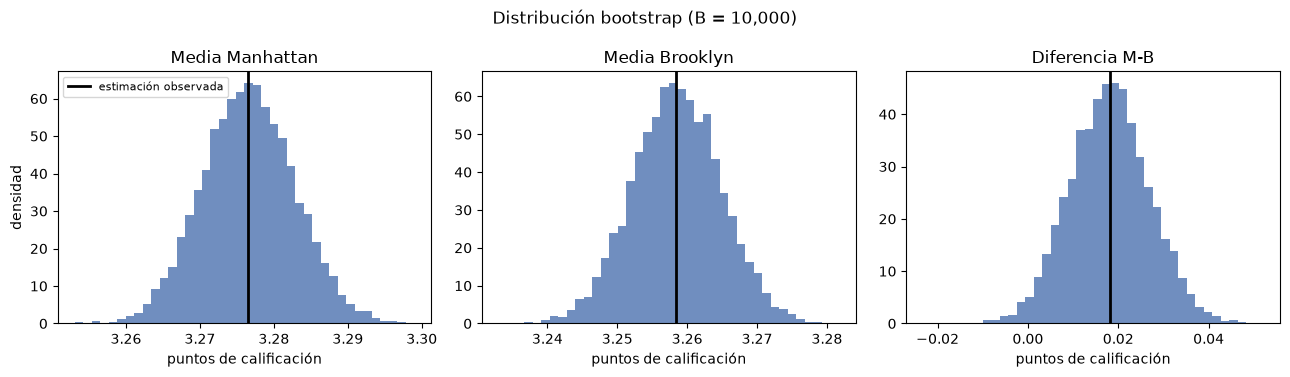

In [6]:
# Distribución de los estadísticos bootstrap
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

for j, (ax, nombre) in enumerate(zip(axes, clasico.index)):
    # Histograma de las réplicas bootstrap
    ax.hist(boot[:, j], bins=40, density=True, color='#4c72b0', alpha=0.8)

    # Línea vertical para la estimación observada
    ax.axvline(clasico.iloc[j]['estimacion'], color='k', lw=2, label='estimación observada')

    ax.set_title(nombre)
    ax.set_xlabel('puntos de calificación')

axes[0].set_ylabel('densidad')
axes[0].legend(fontsize=8)
fig.suptitle(f'Distribución bootstrap (B = {B:,})')
fig.tight_layout()
plt.show()

## 3.3 Comparación con la estimación clásica

In [7]:
# Clásico vs bootstrap, y estabilidad según cantidad de repeticiones
comp = pd.DataFrame({
    'EE_clasico': clasico['EE'],
    'EE_bootstrap': boot_tabla['EE']
})
comp['razon_boot/clasico'] = comp['EE_bootstrap'] / comp['EE_clasico']
mostrar_tabla(comp, decimales=DECIMALES_COMPARACION)

# Estabilidad: EE bootstrap de la diferencia usando las primeras b réplicas
estab = pd.DataFrame({
    'B': [200, 1000, 5000, B],
    'EE_diferencia': [boot[:b, 2].std(ddof=1) for b in [200, 1000, 5000, B]]
})
mostrar_tabla(estab, decimales=DECIMALES_COMPARACION)

,EE_clasico,EE_bootstrap,razon_boot/clasico
Media Manhattan,"0,00619","0,00623","1,00591"
Media Brooklyn,"0,00636","0,00630","0,99133"
Diferencia M-B,"0,00888","0,00883","0,99481"


,B,EE_diferencia
0,200,"0,00911"
1,1000,"0,00887"
2,5000,"0,00870"
3,10000,"0,00883"


¿Hay diferencias relevantes entre ambos enfoques? No, ya que los EE casi coinciden. Esto es esperable, debido a que el estimador es una media y las muestras son muy grandes.

Ventajas del bootstrap: muestra la distribución completa del estimador, no exige fórmula ni normalidad, y se extiende a estadísticos sin fórmula simple.  
  
Limitaciones: depende de que la muestra sea representativa y de observaciones independientes; el resultado tiene un pequeño error numérico por usar $B$ finito, que se estabiliza al aumentar $B$; y requiere más cómputo que la fórmula.

## 4. Simulación Monte Carlo

### 4.1 Idea general
Monte Carlo genera muchas muestras aleatorias de un modelo para estudiar cómo varía un estimador. Aquí lo usamos para analizar la precisión de la diferencia de calificaciones entre Manhattan y Brooklyn.

### 4.2 Pregunta de interés
¿Cómo cambia la precisión de la diferencia estimada entre Manhattan y Brooklyn al aumentar el tamaño muestral?

### 4.3 Modelo y medidas
La calificación de un anuncio toma valores en $\{1,2,3,4,5\}$. Para cada distrito utilizamos las frecuencias observadas de esas notas como probabilidades de generación. Suponemos anuncios independientes y mantenemos fijas esas probabilidades.

Simulamos los conteos de las cinco notas mediante una distribución multinomial. Esto equivale a sortear calificaciones independientes según las probabilidades de cada distrito y contar cuántas veces aparece cada nota.

Generamos muestras de 50, 200, 1.000 y 5.000 anuncios por distrito, además de los tamaños originales: 43.418 de Manhattan y 41.515 de Brooklyn. En cada realización calculamos la diferencia de medias, $\widehat{\Delta}=\overline{Y}_M-\overline{Y}_B$.

La diferencia de referencia del modelo coincide con la observada: 0,0181 puntos. Evaluamos dos medidas:

- Desviación estándar de las diferencias simuladas: cuanto menor es, menor es la variabilidad entre muestras.
- P(error ≤ 0,05): proporción de realizaciones con $|\widehat{\Delta}-\Delta_{\text{modelo}}|\leq 0,05$. Fijamos una tolerancia de 0,05 puntos para esta aplicación.


In [9]:
# Modelo de calificaciones construido con las frecuencias observadas
R = 10_000
tolerancia = 0.05  # error máximo, en puntos, considerado en el ejercicio
valores = np.arange(1, 6)
cuentas_m = np.bincount(M.astype(int), minlength=6)[1:6]
cuentas_b = np.bincount(K.astype(int), minlength=6)[1:6]
p_m = cuentas_m / cuentas_m.sum()
p_b = cuentas_b / cuentas_b.sum()
delta_modelo = M.mean() - K.mean()

def simular(n_m, n_b, R, rng):
    c_m = rng.multinomial(n_m, p_m, size=R)
    c_b = rng.multinomial(n_b, p_b, size=R)
    return c_m @ valores / n_m - c_b @ valores / n_b


In [10]:
# Precisión de la diferencia para distintos tamaños muestrales
escenarios = {
    '50': (50, 50), '200': (200, 200),
    '1000': (1000, 1000), '5000': (5000, 5000),
    'original': (len(M), len(K))
}
rng_mc = np.random.default_rng(SEED_MC)
filas, sims = [], {}
for nombre, (n_m, n_b) in escenarios.items():
    dif = simular(n_m, n_b, R, rng_mc)
    sims[nombre] = dif
    filas.append([nombre, dif.std(ddof=1),
                  (np.abs(dif - delta_modelo) <= tolerancia).mean()])

mc = pd.DataFrame(filas, columns=[
    'escenario', 'DE_diferencia', 'P(error<=0.05)'
]).set_index('escenario')
mostrar_tabla(mc, columnas_porcentaje=['P(error<=0.05)'])

,DE_diferencia,P(error<=0.05)
escenario,,
50,"0,2587","15,56 %"
200,"0,1307","30,15 %"
1000,"0,0579","61,49 %"
5000,"0,0257","94,80 %"
original,"0,0088","100,00 %"


### 4.4 Número de realizaciones y estabilidad
Utilizamos 10.000 realizaciones por escenario. Para una probabilidad estimada con $R$ realizaciones independientes, el error estándar Monte Carlo cumple lo siguiente:

$$
EE_{\mathrm{MC}}=\sqrt{\frac{\widehat{p}(1-\widehat{p})}{R}}
\leq\frac{1}{2\sqrt{R}}.
$$

Con $R=10.000$, este error estándar es como máximo **0,0050**, equivalente a 0,50 puntos porcentuales. Comprobamos además la estabilidad de P(error ≤ 0,05) usando las primeras 1.000, 5.000 y 10.000 realizaciones del escenario de 1.000 anuncios por distrito.

El tamaño muestral determina la precisión de cada estimación; el número de realizaciones determina la precisión de la aproximación Monte Carlo.

,P(error<=0.05),Cambio frente a R anterior (pp)
R,,
1000,"62,60 %",—
5000,"61,90 %","0,70"
10000,"61,49 %","0,41"


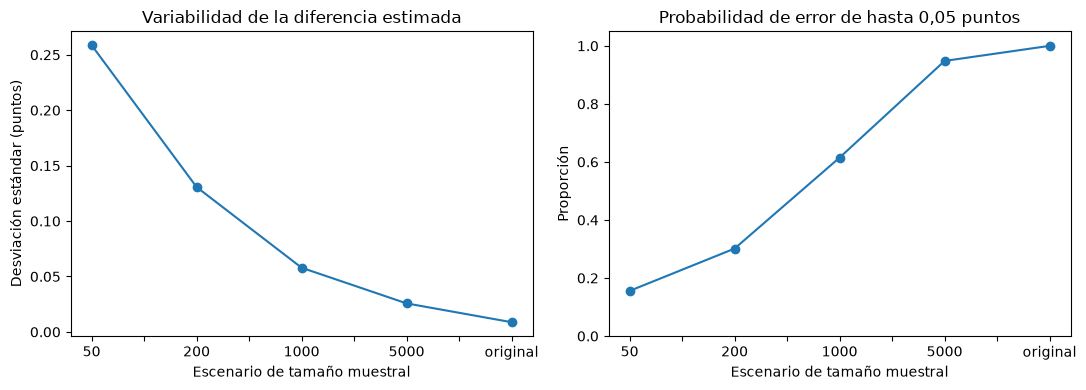

In [11]:
# Estabilidad de la probabilidad con 1.000 anuncios por distrito
aciertos = np.abs(sims['1000'] - delta_modelo) <= tolerancia
estabilidad = pd.DataFrame({
    'R': [1000, 5000, R],
    'P(error<=0.05)': [aciertos[:r].mean() for r in [1000, 5000, R]]
}).set_index('R')
estabilidad['Cambio frente a R anterior (pp)'] = estabilidad['P(error<=0.05)'].diff().abs() * 100
mostrar_tabla(estabilidad, columnas_porcentaje=['P(error<=0.05)'],
              columnas_pp=['Cambio frente a R anterior (pp)'])

# Efecto del tamaño muestral sobre la precisión
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
mc['DE_diferencia'].plot(ax=axes[0], marker='o')
axes[0].set_title('Variabilidad de la diferencia estimada')
axes[0].set_ylabel('Desviación estándar (puntos)')

mc['P(error<=0.05)'].plot(ax=axes[1], marker='o')
axes[1].set_title('Probabilidad de error de hasta 0,05 puntos')
axes[1].set_ylabel('Proporción')
axes[1].set_ylim(0, 1.05)
for ax in axes:
    ax.set_xlabel('Escenario de tamaño muestral')
fig.tight_layout()
plt.show()

### 4.5 Análisis e interpretación

Variabilidad. La desviación estándar de la diferencia disminuye de 0,2587 puntos, con 50 anuncios por distrito, a 0,0088 puntos, con los tamaños originales. Las muestras grandes producen estimaciones más concentradas alrededor de la diferencia del modelo.

Error de estimación. La proporción de realizaciones con un error de hasta 0,05 puntos es 30,15 % con 200 anuncios por distrito y 94,80 % con 5.000. Con los tamaños originales, esa proporción es 100,00 %. Esto describe las simulaciones realizadas; no garantiza ese resultado para cualquier muestra futura.

Estabilidad. Con 1.000 anuncios por distrito, la probabilidad estimada es 62,60 %, 61,90 % y 61,49 % al acumular 1.000, 5.000 y 10.000 realizaciones respectivamente. La diferencia entre las dos últimas estimaciones es de 0,41 puntos porcentuales, lo que apoya la elección de 10.000 realizaciones para el nivel de precisión numérica buscado.

Respuesta a la pregunta. Bajo el modelo definido, aumentar el tamaño muestral mejora la precisión de la diferencia estimada. Su magnitud de referencia permanece en aproximadamente 0,0181 puntos, mientras disminuye la variabilidad de las estimaciones. La tolerancia de 0,05 puntos es mayor que esa diferencia; esta probabilidad mide el error de estimación dentro de la tolerancia elegida.

## 5. Interpretación y conclusiones

Estimación puntual. La calificación media es 3,2765 en Manhattan y 3,2585 en Brooklyn. La diferencia de 0,0181 puntos es pequeña en la escala de 1 a 5, por lo que ambos distritos presentan medias muy cercanas en los datos analizados.

Bootstrap. Con 10.000 remuestras, el error estándar de la diferencia es 0,0088, muy próximo al valor clásico de 0,0089. Ambos métodos entregan estimaciones de precisión similares. El bootstrap permite además visualizar la distribución del estimador mediante el remuestreo.

Monte Carlo. Al aumentar la muestra, la desviación estándar de la diferencia disminuye de 0,2587 puntos, con 50 anuncios por distrito, a 0,0088, con los tamaños originales. La proporción de estimaciones con error de hasta 0,05 puntos respecto del modelo aumenta de 30,15 %, con 200 anuncios por distrito, a 94,80 %, con 5.000.

Conclusión. La diferencia observada entre los distritos es pequeña y su estimación se vuelve más precisa al aumentar el tamaño muestral.

### Limitaciones
- Representatividad: desconocemos cómo se seleccionaron los anuncios del dataset ni por qué faltan algunas calificaciones; los resultados valen para estos datos y sin hacer generalizaciones imprudentes
- Independencia: supone anuncios independientes; anfitriones con varias propiedades o dependencia espacial alterarían los errores estándar.
- Asociación, no causalidad: no controlamos tipo de alojamiento, precio u otras variables.
- Modelo de Monte Carlo: fija las probabilidades empíricas y no incorpora la incertidumbre de haberlas estimado.
- Alcance: el contraste cubre solo dos de los cinco distritos.